In [1]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("ealaxi/banksim1")

print("Path to dataset files:", path)

100%|██████████| 13.1M/13.1M [00:00<00:00, 14.4MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/ealaxi/banksim1/versions/1


In [2]:
%load_ext cuml.accel

[2025-07-03 19:15:01.446] [CUML] [info] cuML: Installed accelerator for sklearn.
[2025-07-03 19:15:37.777] [CUML] [info] cuML: Installed accelerator for umap.
[2025-07-03 19:15:37.881] [CUML] [info] cuML: Installed accelerator for hdbscan.
[2025-07-03 19:15:37.881] [CUML] [info] cuML: Successfully initialized accelerator.


In [3]:
import os
os.listdir(path)

['bsNET140513_032310.csv', 'bs140513_032310.csv']

In [4]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler, LabelEncoder

# Load data
df= pd.read_csv(path+"/bs140513_032310.csv")

In [5]:
df.head()

,step,customer,age,gender,zipcodeOri,merchant,zipMerchant,category,amount,fraud
0,0,'C1093826151','4','M','28007','M348934600','28007','es_transportation',4.55,0
1,0,'C352968107','2','M','28007','M348934600','28007','es_transportation',39.68,0
2,0,'C2054744914','4','F','28007','M1823072687','28007','es_transportation',26.89,0
3,0,'C1760612790','3','M','28007','M348934600','28007','es_transportation',17.25,0
4,0,'C757503768','5','M','28007','M348934600','28007','es_transportation',35.72,0


In [6]:
print("Dataset Info:")
print(df.info())
print("\nFirst 5 rows:")
print(df.head())
print("\nMissing Values:")
print(df.isnull().sum())


Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 594643 entries, 0 to 594642
Data columns (total 10 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   step         594643 non-null  int64  
 1   customer     594643 non-null  object 
 2   age          594643 non-null  object 
 3   gender       594643 non-null  object 
 4   zipcodeOri   594643 non-null  object 
 5   merchant     594643 non-null  object 
 6   zipMerchant  594643 non-null  object 
 7   category     594643 non-null  object 
 8   amount       594643 non-null  float64
 9   fraud        594643 non-null  int64  
dtypes: float64(1), int64(2), object(7)
memory usage: 45.4+ MB
None

First 5 rows:
   step       customer  age gender zipcodeOri       merchant zipMerchant  \
0     0  'C1093826151'  '4'    'M'    '28007'   'M348934600'     '28007'   
1     0   'C352968107'  '2'    'M'    '28007'   'M348934600'     '28007'   
2     0  'C2054744914'  '4'    'F'    '28007'  '

In [7]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors
import matplotlib.pyplot as plt
import seaborn as sns


# Clean quoted strings
str_cols = ['customer', 'age', 'gender', 'zipcodeOri', 'merchant', 'zipMerchant', 'category']
for col in str_cols:
    df[col] = df[col].str.strip("'")

# Feature engineering
df['hour'] = df['step'] % 24  # Extract transaction hour
df['is_weekend'] = (df['step'] % 7 >= 5).astype(int)  # Weekend flag

# Create merchant-customer frequency features
df['merch_cust_count'] = df.groupby(['merchant', 'customer'])['customer'].transform('count')
df['merch_cust_freq'] = df['merch_cust_count'] / df.groupby('customer')['customer'].transform('count')

# Create zipcode distance feature
df['same_zip'] = (df['zipcodeOri'] == df['zipMerchant']).astype(int)

# Prepare features for clustering
features = df[['amount', 'hour', 'is_weekend', 'merch_cust_freq', 'same_zip']]

# Encode categorical features
encoder = OneHotEncoder(drop='first', sparse_output=False)
cat_features = encoder.fit_transform(df[['age', 'gender', 'category']])
cat_feature_names = encoder.get_feature_names_out(['age', 'gender', 'category'])

# Combine all features
features = pd.concat([
    features.reset_index(drop=True),
    pd.DataFrame(cat_features, columns=cat_feature_names)
], axis=1)

# Scale features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(features)

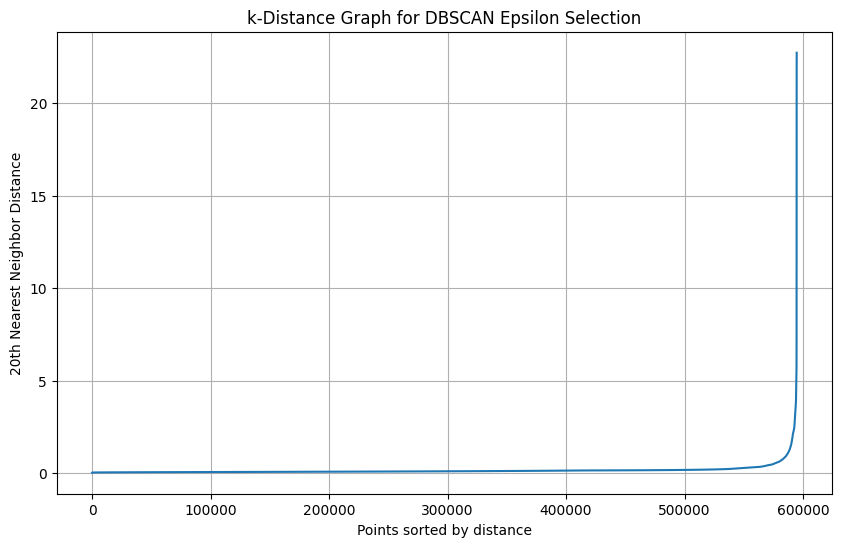

In [8]:
# Find optimal eps using k-distance graph
nn = NearestNeighbors(n_neighbors=20)
nn.fit(X_scaled)
distances, _ = nn.kneighbors(X_scaled)
distances = np.sort(distances[:, -1], axis=0)

plt.figure(figsize=(10, 6))
plt.plot(distances)
plt.xlabel('Points sorted by distance')
plt.ylabel('20th Nearest Neighbor Distance')
plt.title('k-Distance Graph for DBSCAN Epsilon Selection')
plt.grid(True)
plt.show()


[2025-07-03 19:16:04.226] [CUML] [warning] Batch size limited by the chosen integer type (4 bytes). 4211 -> 3611. Using the larger integer type might result in better performance
Clusters found: 32, Noise points: 595
         fraud_rate  total_transactions   avg_amount
cluster                                             
 25        0.949791                 478   288.418033
-1         0.726050                 595  2176.173815
 28        0.705056                 356  1262.868315
 7         0.498426                3812   215.979234
 20        0.431694                 183   197.936612
 5         0.313631                1658   202.104572
 12        0.253731                  67   155.460299
 2         0.246528                 864   132.729410
 24        0.179487                  39    83.950000
 11        0.142551                1866   152.419507


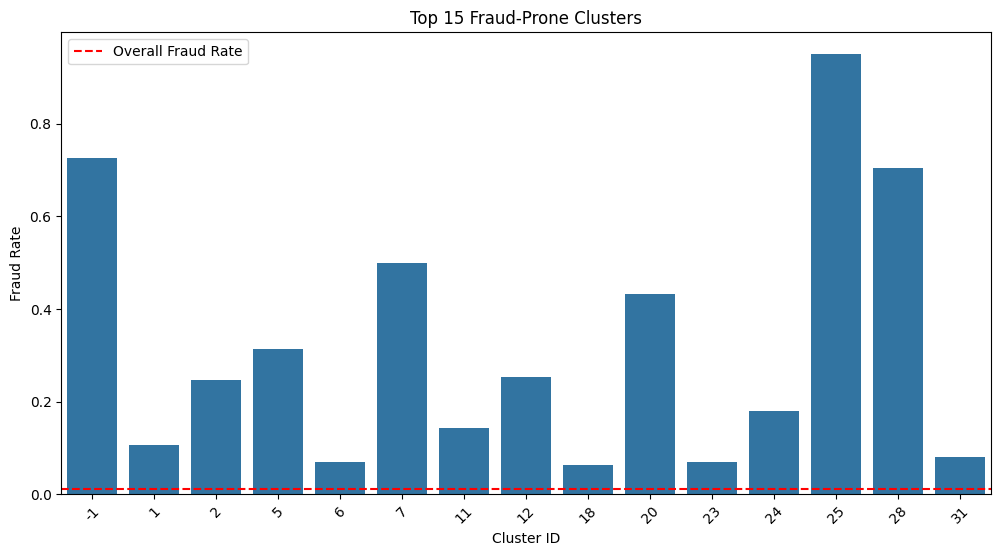


Noise points fraud rate: 72.61%
Noise captures 6.0% of total fraud


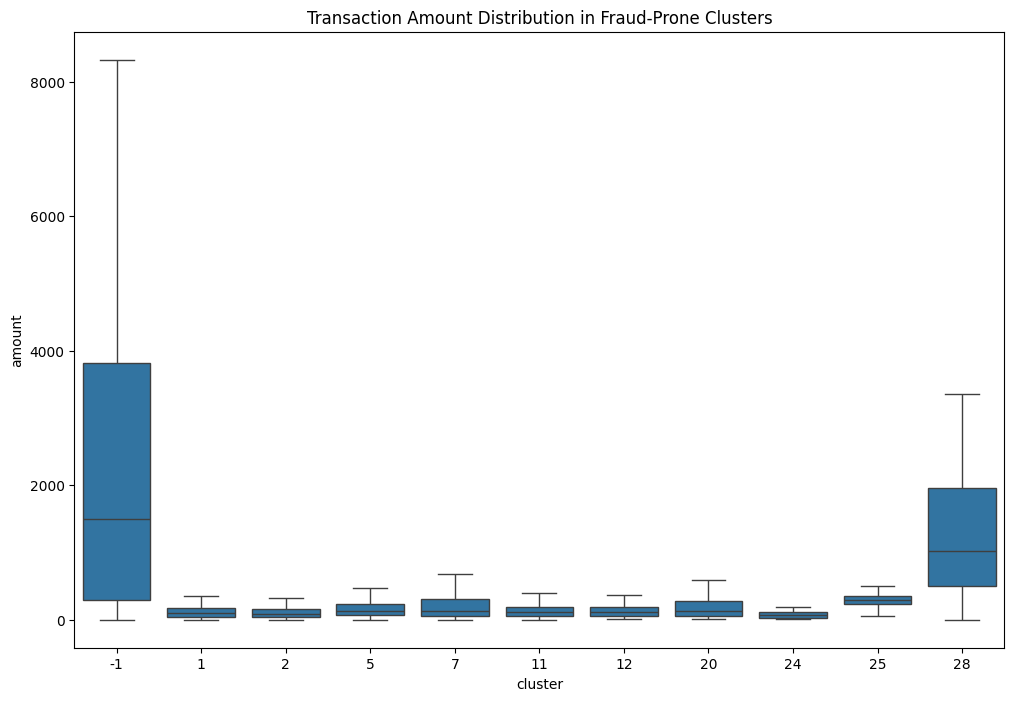

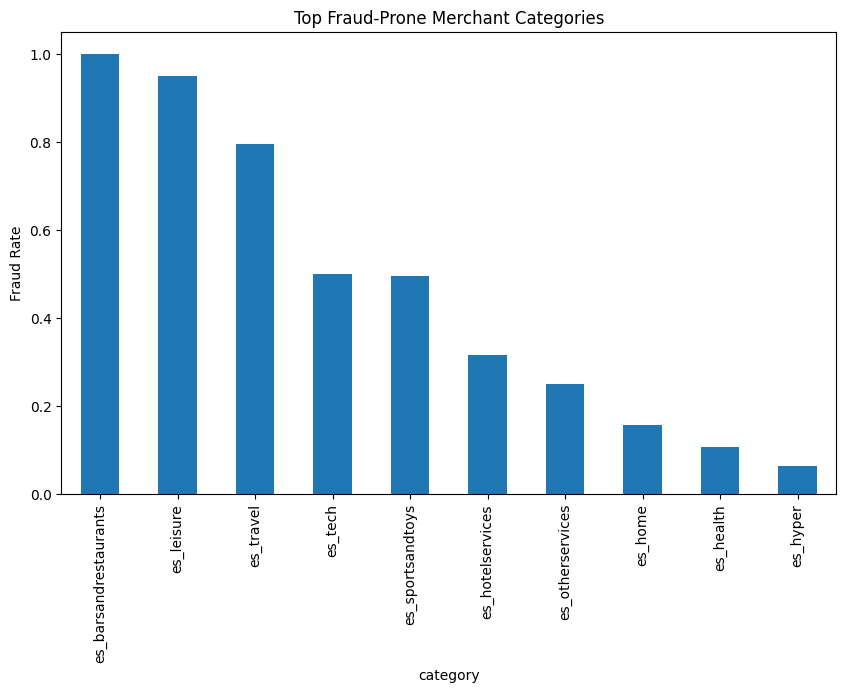

In [9]:
# Initialize and fit DBSCAN (adjust eps based on k-distance elbow)
db = DBSCAN(eps=3.5, min_samples=25, metric='euclidean')  # Tune these
clusters = db.fit_predict(X_scaled)

# Add results to dataframe
df['cluster'] = clusters
n_clusters = len(set(clusters)) - (1 if -1 in clusters else 0)
n_noise = (clusters == -1).sum()
print(f"Clusters found: {n_clusters}, Noise points: {n_noise}")

# Analyze fraud by cluster
cluster_analysis = df.groupby('cluster').agg(
    fraud_rate=('fraud', 'mean'),
    total_transactions=('fraud', 'count'),
    avg_amount=('amount', 'mean')
).sort_values('fraud_rate', ascending=False)

# Display top fraud-prone clusters
print(cluster_analysis.head(10))

# Visualize fraud clusters
plt.figure(figsize=(12, 6))
sns.barplot(x=cluster_analysis.index[:15],
            y=cluster_analysis['fraud_rate'][:15])
plt.axhline(df['fraud'].mean(), color='r', linestyle='--',
            label='Overall Fraud Rate')
plt.xlabel('Cluster ID')
plt.ylabel('Fraud Rate')
plt.title('Top 15 Fraud-Prone Clusters')
plt.xticks(rotation=45)
plt.legend()
plt.show()

# Analyze noise points (potential fraud)
noise_data = df[clusters == -1]
print(f"\nNoise points fraud rate: {noise_data['fraud'].mean():.2%}")
print(f"Noise captures {noise_data['fraud'].sum()/df['fraud'].sum():.1%} of total fraud")

# Feature distribution in fraud clusters
fraud_clusters = cluster_analysis[cluster_analysis['fraud_rate'] > 0.1].index
fraud_cluster_data = df[df['cluster'].isin(fraud_clusters)]

plt.figure(figsize=(12, 8))
sns.boxplot(x='cluster', y='amount', data=fraud_cluster_data, showfliers=False)
plt.title('Transaction Amount Distribution in Fraud-Prone Clusters')
plt.show()

# Merchant categories in fraud clusters
top_fraud_categories = (fraud_cluster_data.groupby('category')['fraud']
                        .mean()
                        .sort_values(ascending=False)
                        .head(10))

plt.figure(figsize=(10, 6))
top_fraud_categories.plot(kind='bar')
plt.title('Top Fraud-Prone Merchant Categories')
plt.ylabel('Fraud Rate')
plt.show()

In [ ]:
# Tune parameters based on fraud recall
def optimize_dbscan(eps_values, min_samples_values):
    results = []
    for eps in eps_values:
        for min_samp in min_samples_values:
            db = DBSCAN(eps=eps, min_samples=min_samp)
            clusters = db.fit_predict(X_scaled)
            fraud_in_noise = df.loc[(clusters == -1), 'fraud'].sum()
            total_fraud = df['fraud'].sum()
            recall = fraud_in_noise / total_fraud
            results.append((eps, min_samp, recall))

    return pd.DataFrame(results, columns=['eps', 'min_samples', 'recall'])

# Test parameter ranges
eps_range = np.arange(3.0, 4.5, 0.2)
min_samples_range = [20, 25, 30, 35]
optimization_results = optimize_dbscan(eps_range, min_samples_range)

# Visualize optimization
plt.figure(figsize=(10, 6))
sns.heatmap(optimization_results.pivot('eps', 'min_samples', 'recall'),
            annot=True, cmap='viridis')
plt.title('Fraud Recall by DBSCAN Parameters')
plt.show()